# 🛢️ OilyGiant: Qual a melhor região para novos poços de petróleo
Nesse projeto, estarei atuando como uma funcionária de uma empresa de mineração , cujo objetivo é encontrar os melhores lugares para o desenvolvimento de novos poços de petróleo.  

Para realizar essa tarefa vou executar os seguintes etapas:
1. Carregamento e preparação dos dados
2. Treinamento e validação do modelo por região
3. Preparação para o cálculo de lucro
4. Cálculo de lucro com os 200 melhores poços
5. Riscos e lucro com bootstrapping
6. Elaborar conclusão geral

Há algumas condições que preciso considerar para encontrar os melhores lugares:
- Apenas regressão linear deve ser usada para o treinamento do modelo.
- Ao explorar a região, um estudo de 500 pontos é realizado e os melhores 200 pontos são selecionados para calcular o lucro.
- O orçamento para o desenvolvimento de 200 poços de petróleo é 100 milhões de dólares.
- Um barril de petróleo bruto traz 4.5 dólares de receita. A receita de uma unidade de produto é 4.500 dólares (o volume de reservas está em milhares de barris).
- Depois de ter avaliado os riscos, mantenha apenas as regiões com o risco de perdas inferior a 2.5%. Entre aquelas que se enquadram no critério, você precisa selecionar a região com o lucro médio mais alto.



## 1. Carregamento e preparação dos dados
Primeiramente, vou carregar os dados fornecidos e examinar os conjuntos de dados para verificar:
- Dados ausentes
- Dados duplicados
- Formatação
Serão carregados três conjuntos de dados representando três regiões e agrupadas em um dicionários chamado `data` (usando uma função `load_data`). Isso permite que que os dados quando exibidos estejam ligados a cada região  e evita duplicação de códigos.

In [197]:
# importar as bibliotecas necessárias
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

RANDOM_STATE = 12345

In [198]:
# Função para carregar os dados do CSV em arquivos separados por região
def load_data(filename):
    """Lê o CSV tentando o caminho da plataforma e depois o caminho local."""
    try:
        return pd.read_csv(f'dataset/{filename}')
    except FileNotFoundError:
        return pd.read_csv(filename)

files = {'Região 0': 'geo_data_0.csv',
         'Região 1': 'geo_data_1.csv',
         'Região 2': 'geo_data_2.csv'}

data = {region: load_data(file) for region, file in files.items()}

### 1.1  Inspeção inicial dos dados

In [199]:
# função para examinar os dados e verificar se há valores ausentes
for region, df in data.items():
    print(f"Região: {region}")
    print(f"Dimensões do DataFrame: {df.shape}")
    df.info()
    display(df.head())
    print('Valores nulos encontrados:',df.isnull().sum().sum())
    print('Linhas duplicadas encontradas:', df.duplicated().sum())
    print("IDs duplicados encontrados:", df['id'].duplicated().sum())
    print(df.describe().round(2))
    print("\n")

Região: Região 0
Dimensões do DataFrame: (100000, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


,id,f0,f1,f2,product
0,txEyH,0.705745,-0.497823,1.221170,105.280062
1,2acmU,1.334711,-0.340164,4.365080,73.037750
2,409Wp,1.022732,0.151990,1.419926,85.265647
3,iJLyR,-0.032172,0.139033,2.978566,168.620776
4,Xdl7t,1.988431,0.155413,4.751769,154.036647


Valores nulos encontrados: 0
Linhas duplicadas encontradas: 0
IDs duplicados encontrados: 10
              f0         f1         f2    product
count  100000.00  100000.00  100000.00  100000.00
mean        0.50       0.25       2.50      92.50
std         0.87       0.50       3.25      44.29
min        -1.41      -0.85     -12.09       0.00
25%        -0.07      -0.20       0.29      56.50
50%         0.50       0.25       2.52      91.85
75%         1.07       0.70       4.72     128.56
max         2.36       1.34      16.00     185.36


Região: Região 1
Dimensões do DataFrame: (100000, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), 

,id,f0,f1,f2,product
0,kBEdx,-15.001348,-8.276000,-0.005876,3.179103
1,62mP7,14.272088,-3.475083,0.999183,26.953261
2,vyE1P,6.263187,-5.948386,5.001160,134.766305
3,KcrkZ,-13.081196,-11.506057,4.999415,137.945408
4,AHL4O,12.702195,-8.147433,5.004363,134.766305


Valores nulos encontrados: 0
Linhas duplicadas encontradas: 0
IDs duplicados encontrados: 4
              f0         f1         f2    product
count  100000.00  100000.00  100000.00  100000.00
mean        1.14      -4.80       2.49      68.83
std         8.97       5.12       1.70      45.94
min       -31.61     -26.36      -0.02       0.00
25%        -6.30      -8.27       1.00      26.95
50%         1.15      -4.81       2.01      57.09
75%         8.62      -1.33       4.00     107.81
max        29.42      18.73       5.02     137.95


Região: Região 2
Dimensões do DataFrame: (100000, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), o

,id,f0,f1,f2,product
0,fwXo0,-1.146987,0.963328,-0.828965,27.758673
1,WJtFt,0.262778,0.269839,-2.530187,56.069697
2,ovLUW,0.194587,0.289035,-5.586433,62.871910
3,q6cA6,2.236060,-0.553760,0.930038,114.572842
4,WPMUX,-0.515993,1.716266,5.899011,149.600746


Valores nulos encontrados: 0
Linhas duplicadas encontradas: 0
IDs duplicados encontrados: 4
              f0         f1         f2    product
count  100000.00  100000.00  100000.00  100000.00
mean        0.00      -0.00       2.50      95.00
std         1.73       1.73       3.47      44.75
min        -8.76      -7.08     -11.97       0.00
25%        -1.16      -1.17       0.13      59.45
50%         0.01      -0.01       2.48      94.93
75%         1.16       1.16       4.86     130.60
max         7.24       7.84      16.74     190.03




#### 1.1.4 Inspeção de ID duplicados

 Examinamos os conjuntos de dados das três regiões não encontramos: dados ausentes ou formatos inconsistentes, porém detectamos ID (identificador unívoco de poço de petróleo) duplicados. Como não detectamos linhas que tenham dados totalmente duplicados, só os ID, vamos avaliar com maior detalhamento esses casos

In [200]:
# iterando sobre cada região para encontrar IDs duplicados
for region, df in data.items():
    dup_ids=df[df['id'].duplicated(keep=False)].sort_values(by='id')
    print(f'{region}: {dup_ids["id"].nunique()} IDS repetidos encontrados, {len(dup_ids)} linhas duplicadas encontradas.')
    display(dup_ids)

Região 0: 10 IDS repetidos encontrados, 20 linhas duplicadas encontradas.


,id,f0,f1,f2,product
66136,74z30,1.084962,-0.312358,6.990771,127.643327
64022,74z30,0.741456,0.459229,5.153109,140.771492
51970,A5aEY,-0.180335,0.935548,-2.094773,33.020205
3389,A5aEY,-0.039949,0.156872,0.209861,89.249364
69163,AGS9W,-0.933795,0.116194,-3.655896,19.230453
42529,AGS9W,1.454747,-0.479651,0.683380,126.370504
931,HZww2,0.755284,0.368511,1.863211,30.681774
7530,HZww2,1.061194,-0.373969,10.430210,158.828695
63593,QcMuo,0.635635,-0.473422,0.862670,64.578675
1949,QcMuo,0.506563,-0.323775,-2.215583,75.496502


Região 1: 4 IDS repetidos encontrados, 8 linhas duplicadas encontradas.


,id,f0,f1,f2,product
5849,5ltQ6,-3.435401,-12.296043,1.999796,57.085625
84461,5ltQ6,18.213839,2.191999,3.993869,107.813044
1305,LHZR0,11.170835,-1.945066,3.002872,80.859783
41906,LHZR0,-8.989672,-4.286607,2.009139,57.085625
2721,bfPNe,-9.494442,-5.463692,4.006042,110.992147
82178,bfPNe,-6.202799,-4.820045,2.995107,84.038886
47591,wt4Uk,-9.091098,-8.109279,-0.002314,3.179103
82873,wt4Uk,10.259972,-9.376355,4.994297,134.766305


Região 2: 4 IDS repetidos encontrados, 8 linhas duplicadas encontradas.


,id,f0,f1,f2,product
45404,KUPhW,0.231846,-1.698941,4.990775,11.716299
55967,KUPhW,1.211150,3.176408,5.543540,132.831802
11449,VF7Jo,2.122656,-0.858275,5.746001,181.716817
49564,VF7Jo,-0.883115,0.560537,0.723601,136.233420
44378,Vcm5J,-1.229484,-2.439204,1.222909,137.968290
95090,Vcm5J,2.587702,1.986875,2.482245,92.327572
28039,xCHr8,1.633027,0.368135,-2.378367,6.120525
43233,xCHr8,-0.847066,2.101796,5.597130,184.388641


**DECISÃO:** Após, avaliarmos cada linha que teve o ID duplicados constatamos que registros com mesmo ´id´ não são consequência de um erro de duplicação de dados ou de erros de digitação. São linhas de poços diferentes que receberam o mesmo código: cada par tem valores diferentes de características e de `product`. Ao verificar os valores os registro mostram coerência de valores. Como o valor `id` é apenas identificador a retirada de linhas seria perder informações. Desta forma as linhas foram mantidas.

### 1.2 Correlação das características com a variável objetivo
O objetivo para fazer uma correlação das características com a variável objetivo antes de treinar os modelos para verificar as relações ente `f0`, `f1`,`f2` com o volume das reservas (`product). Como usaremos uma regressão linear para modelo, ele captura relações lineares entre as variáveis.A correlação de Pearson uma medida adequada para antecipar o desempenho esperado do modelo em cada região: se a correlação foi alta, menor a tendencia de erros na predição. Essa etapa fornece uma bases para interpretar, mais adiante, as diferenças de REQM entre regiões e, as diferenças de riscos e lucro obtidas no bootstrapping

In [201]:
# Iteração para correlação entre as variáveis
for region, df in data.items():
    print(f"Região: {region}")
    display(df.drop(columns=['id']).corr()['product'].round(3).to_frame("Correlação com a variável alvo"))

Região: Região 0


,Correlação com a variável alvo
f0,0.144
f1,-0.192
f2,0.484
product,1.000


Região: Região 1


,Correlação com a variável alvo
f0,-0.030
f1,-0.010
f2,0.999
product,1.000


Região: Região 2


,Correlação com a variável alvo
f0,-0.002
f1,-0.001
f2,0.446
product,1.000


### Observações sobre etapa de preparação dos dados
Nas três regiões não foram encontrados valores ausentes, ne formatos de dados incoerentes. Identificamos `id` repetidos em todos os conjuntos de dados, mas verificamos que os registros se tratavam e poços distintos, com valores de características e de `product` diferentes e coerentes entre si. Por isso, as linhas foram mantidas.

A análises descritiva mostrou que o volume médio de reservas por poço é de 92,50; 68,83 e 95 mil barris nas regiões 0,1 e 2. Todos abaixo do ponto de equilíbrio de 111,1 mil barris. O desvio padrão de `product` é semelhante nas três regiões (entorno de 44 a 46), indicando alta dispersão dos valores. A região 1 apresenta o menor teto de reservas: máximo de 137,95 contra 185,36(região 0) e 190,03(região 2). 

Quanto as caraterísticas as escalas são bem diferentes entre as regiões. Por exemplo, f0 tem desvio padrão de 8,97 na Região 1 e de 0,87 na Região 0, o que justifica a padronização antes do treino

A analise de correlação mostrou que, nas regiões 0 e 2, a característica `f2` tem correlação moderada com `product`(0,48 e 0,45 respectivamente), enquanto para as outras características a correlação é fraca ou nula. Na região1 , `f2` tem uma correlação praticamente perfeita com `product`(~ 0.999), indicando uma relação quase linear. Como o modelo exigido é uma regressão linear, espera-se que o erro de predição (REQM) seja muito menor na Região 1 do que nas demais.

## 2. Treinamento e teste do modelo por região

### 2.1 Região 0: divisão dos dados em treino e validação(75:25)

In [202]:
df_0 = data['Região 0']

features = df_0.drop(columns=['id', 'product'])
target = df_0['product']

features_train_0, features_valid_0, target_train_0, target_valid_0 = train_test_split(features, target, test_size=0.25, random_state=RANDOM_STATE)

# Padronização dos dados
scaler = StandardScaler().fit(features_train_0)
features_train_0_scaled = scaler.transform(features_train_0)
features_valid_0_scaled = scaler.transform(features_valid_0)    

print("Dimensões do conjunto de treino:", features_train_0_scaled.shape)
print("Dimensões do conjunto de validação:", features_valid_0_scaled.shape)


Dimensões do conjunto de treino: (75000, 3)
Dimensões do conjunto de validação: (25000, 3)


### 2.2 Região 0: treino do modelo

In [203]:
model_0 = LinearRegression().fit(features_train_0_scaled, target_train_0)
predictions_0 = model_0.predict(features_valid_0_scaled)

#Salvar previsões do modelo
# Guardados em arrays alinhados por posição (usados nas etapas 4 e 5)
target_valid_0 = target_valid_0.to_numpy()

# volume médio previsto e REQM
rmse_0 = mean_squared_error(target_valid_0, predictions_0) ** 0.5

print(f'Volume médio previsto: {predictions_0.mean():.2f} mil barris')
print(f'Volume médio real:     {target_valid_0.mean():.2f} mil barris')
print(f'REQM do modelo:        {rmse_0:.2f} mil barris')


print("Verificação de  sanidade:")
# Modelo constante: prevê a média do treino para todos os poços da validação
baseline_pred_0 = np.full(len(target_valid_0), target_train_0.mean())
rmse_baseline_0 = mean_squared_error(target_valid_0, baseline_pred_0) ** 0.5

print(f'REQM do modelo constante: {rmse_baseline_0:.2f} mil barris')
print(f'Redução do erro:          {(1 - rmse_0 / rmse_baseline_0):.1%}')

Volume médio previsto: 92.59 mil barris
Volume médio real:     92.08 mil barris
REQM do modelo:        37.58 mil barris
Verificação de  sanidade:
REQM do modelo constante: 44.29 mil barris
Redução do erro:          15.2%


#### Observações resultados para região 0:
O modelo treinado e validado para região 0, estimou um volume médio de 92,59 mil barris, o que foi um valor próximo ao real de 92,08 mil barris.Isso indica que o modelo não apresentam viés relevante na média. No entanto, ao examinar a raiz do erro quadrático médio (REQM) de 37,58 mil barris o que representa cerca de 41% de volume médio, o que mostra uma baixa precisão. Quando comparamos com o modelo constante á uma redução de 15.2%, indicando que as características fornecem informações uteis, mass com um ganho modesto. Esse resultado é coerentes com a analises de correlação em que encontramos uma relação moderada entre `f2` e product (0,48) e com a correlação fraca de `f0` e `f1`.

### 2.3 Costrução de modelos para as regiões 1 e 2

In [204]:
# função para treinar e avaliar o modelo para cada região
def train_and_evaluate_model(df, region):
    """Passos 2.1 a 2.4 para uma região, com verificação de sanidade (modelo constante). Retorna target_valid, predictions e rmse."""
    features = df.drop(columns=['id', 'product'])
    target = df['product']
    features_train, features_valid, target_train, target_valid = train_test_split(features, target, test_size=0.25, random_state=RANDOM_STATE)

    # Padronização dos dados
    scaler = StandardScaler()
    features_train_scaled = scaler.fit_transform(features_train)
    features_valid_scaled = scaler.transform(features_valid)    

    #modelo de regressão linear
    model = LinearRegression().fit(features_train_scaled, target_train)
    predictions = model.predict(features_valid_scaled)
    rmse = mean_squared_error(target_valid, predictions) ** 0.5

    #verificação de sanidade: modelo constante
    baseline_pred = np.full(len(target_valid), target_train.mean())
    rmse_baseline = mean_squared_error(target_valid, baseline_pred) ** 0.5

    print(f'Região: {region}')
    print("Dimensões do conjunto de treino:", features_train_scaled.shape)
    print("Dimensões do conjunto de validação:", features_valid_scaled.shape)
    print(f'Volume médio previsto:    {predictions.mean():.2f} mil barris')
    print(f'Volume médio real:        {target_valid.mean():.2f} mil barris')
    print(f'REQM do modelo:           {rmse:.2f} mil barris')
    print('Verificação de sanidade')
    print(f'REQM do modelo constante: {rmse_baseline:.2f} mil barris')
    print(f'Redução do erro:          {1 - rmse / rmse_baseline:.1%}\n')

    return target_valid.to_numpy(), predictions, rmse, rmse_baseline


In [205]:
# Região 0 pela função: confere se reproduz o passo a passo manual da etapa 2.1-2.2
target_check_0, predictions_check_0, rmse_check_0, rmse_baseline_check_0 = train_and_evaluate_model(data['Região 0'], 'Região 0')

assert np.allclose(predictions_0, predictions_check_0)
assert np.isclose(rmse_0, rmse_check_0)
print('A função reproduz exatamente o resultado manual da Região 0.')

Região: Região 0
Dimensões do conjunto de treino: (75000, 3)
Dimensões do conjunto de validação: (25000, 3)
Volume médio previsto:    92.59 mil barris
Volume médio real:        92.08 mil barris
REQM do modelo:           37.58 mil barris
Verificação de sanidade
REQM do modelo constante: 44.29 mil barris
Redução do erro:          15.2%

A função reproduz exatamente o resultado manual da Região 0.


In [206]:
# previsões para regiões
target_valid_1, predictions_1, rmse_1, rmse_baseline_1 = train_and_evaluate_model(data['Região 1'], 'Região 1')
target_valid_2, predictions_2, rmse_2, rmse_baseline_2 = train_and_evaluate_model(data['Região 2'], 'Região 2')

Região: Região 1
Dimensões do conjunto de treino: (75000, 3)
Dimensões do conjunto de validação: (25000, 3)
Volume médio previsto:    68.73 mil barris
Volume médio real:        68.72 mil barris
REQM do modelo:           0.89 mil barris
Verificação de sanidade
REQM do modelo constante: 46.02 mil barris
Redução do erro:          98.1%

Região: Região 2
Dimensões do conjunto de treino: (75000, 3)
Dimensões do conjunto de validação: (25000, 3)
Volume médio previsto:    94.97 mil barris
Volume médio real:        94.88 mil barris
REQM do modelo:           40.03 mil barris
Verificação de sanidade
REQM do modelo constante: 44.90 mil barris
Redução do erro:          10.9%



### 2.4 Consolidação dos resultados

In [207]:
results = {
    'Região 0': {'target': target_valid_0, 'pred': predictions_0, 'rmse': rmse_0},
    'Região 1': {'target': target_valid_1, 'pred': predictions_1, 'rmse': rmse_1},
    'Região 2': {'target': target_valid_2, 'pred': predictions_2, 'rmse': rmse_2},
}

pd.DataFrame({
    region: {'Volume médio previsto': r['pred'].mean(),
             'Volume médio real': r['target'].mean(),
             'REQM': r['rmse']}
    for region, r in results.items()
}).T.round(2)

,Volume médio previsto,Volume médio real,REQM
Região 0,92.59,92.08,37.58
Região 1,68.73,68.72,0.89
Região 2,94.97,94.88,40.03


#### Conclusões da etapa de modelo:
Nas três regiões, o volume médio previsto ficou muito proximo dos valores reais, o que mostra que os modelos construídos não apresentam um viés relevante. Para a região 1, o REQM foi de 0,89 mil barris (cerca de 1,3% da média), com redução de 98,1% do erro em relação ao modelo constante. Esse resultado é coerente com a correlação de 0,999 entre `f2` e `product`. Para as demais regiões, o valores foram de 37,58 (região 0) e 40,03 mil barris (região 2), representando cerca de 41% e 42% do volume médio, com reduções de 15,2% e 10,9%, quando comparado ao modelo constante. Por outro lado, a Região 1 tem o menor volume médio de reservas (68,7 mil barris), enquanto as Regiões 0 e 2 têm médias próximas de 92 e 95 mil barris. Assim, a região mais previsível não é necessariamente a mais lucrativa, o que será avaliado nas próximas etapas.

## 3. Preparação dos dados para o cálculo do lucro
Para examinarmos o lucro das regiões, os valores importantes para os cálculos serão armazenados em variáveis separadas. 
Para que cada um serve

- `BUDGET`, `N_WELLS`:	ponto de equilíbrio e cálculo do lucro (receita − orçamento)

- `REVENUE_PER_UNIT`:	converte volume (mil barris) em dinheiro

- `BREAK_EVEN_PER_WELL`:	comparação com o volume médio de cada região

- `N_EXPLORE`:	tamanho de cada amostra no bootstrapping (etapa 5)

- `N_BOOTSTRAP`, `CONFIDENCE`:	número de repetições e intervalo de confiança de 95%

- `LOSS_RISK_LIMIT`: filtro de regiões com risco abaixo de 2,5%

In [208]:
BUDGET = 100_000_000          # orçamento para desenvolver 200 poços (USD)
N_WELLS = 200                 # poços selecionados para desenvolvimento
N_EXPLORE = 500               # pontos estudados na exploração de cada região
REVENUE_PER_UNIT = 4_500      # receita por unidade (1 unidade = 1000 barris x USD 4,50)
LOSS_RISK_LIMIT = 2.5         # risco máximo de prejuízo aceito (%)
N_BOOTSTRAP = 1000            # amostras de bootstrapping
CONFIDENCE = 0.95             # nível do intervalo de confiança

INVESTMENT_PER_WELL = BUDGET / N_WELLS                      # 500.000 USD por poço
BREAK_EVEN_PER_WELL = INVESTMENT_PER_WELL / REVENUE_PER_UNIT   # ≈ 111,1 unidades por poço

In [209]:
# Comparação com o volume médio (etapa 3)
for region, df in data.items():
    mean_volume = df['product'].mean()
    print(f'{region}: média = {mean_volume:.2f} | mínimo necessário = {BREAK_EVEN_PER_WELL:.2f} '
          f'| diferença = {mean_volume - BREAK_EVEN_PER_WELL:.2f}')

Região 0: média = 92.50 | mínimo necessário = 111.11 | diferença = -18.61
Região 1: média = 68.83 | mínimo necessário = 111.11 | diferença = -42.29
Região 2: média = 95.00 | mínimo necessário = 111.11 | diferença = -16.11


In [210]:
#calcule a proporção de poços acima do ponto de equilíbrio em cada região
for region, df in data.items():
    share = (df['product'] > BREAK_EVEN_PER_WELL).mean()
    print(f'{region}: {share:.1%} dos poços acima de {BREAK_EVEN_PER_WELL:.1f} unidades')

Região 0: 36.6% dos poços acima de 111.1 unidades
Região 1: 16.5% dos poços acima de 111.1 unidades
Região 2: 38.2% dos poços acima de 111.1 unidades


**CONCLUSÕES PARA PREPARAÇÃO DOS DADOS PARA O LUCRO**

O ponto de equilíbrio da extração é o valor mínimo de reservas por poço em que a receita cobre o investimento. A partir dessa quantidade, a empresa passa a ter lucro. O cálculo é:

Investimento por poço: USD 100.000.000 ÷ 200 poços = USD 500.000 por poço;
Receita por unidade de product: 1 unidade = 1.000 barris × USD 4,50 = USD 4.500;
Unidades necessárias por poço: USD 500.000 ÷ USD 4.500 ≈ 111,1 unidades.

Para que a receita de 200 poços cubra os 100 milhões de dólares, cada poço precisa render, no mínimo, 111,1 mil barris para não haver prejuízo.

Ao examinar a média de cada região, nenhuma delas atinge o valor mínimo. A Região 1 tem a menor média, com diferença de 42,29 mil barris para o mínimo necessário; nas Regiões 0 e 2, as médias estão mais próximas, com diferenças de 18,61 e 16,11 mil barris, respectivamente. Essas diferenças mostram que desenvolver poços escolhidos aleatoriamente poderia trazer prejuízo à empresa. Portanto, é necessário usar o modelo para selecionar apenas os poços com maior potencial em cada região.

Observando a proporção de poços com product acima de 111,1 unidades, os valores variam entre regiões. A Região 2 tem a maior proporção (cerca de 38%), seguida pela Região 0 (36,6%). A Região 1 tem a menor: apenas 16,5% dos poços superam 111,1 unidades.

## 4. Lucro potencial dos 200 melhores poços

**origem dos dados para essa etapa:**

Os cálculos de lucro usam os resultados obtidos na etapa 2, armazenados no dicionário `results`. Para cada região, ele contém as **predições** do modelo de regressão linear para o conjunto de validação (25% dos poços que o modelo não viu durante os treinamento) e os volumes reais de reservas (`product`) dos mesmos poços. Esse conjunto simula poços ainda não perfurados: na prática, a empresa só conhece as predições antes de decidir onde investir, mas o lucro depende do volume que de fato existe em cada poço. Por isso, a seleção dos 200 poços é feita com base nas predições mais altas, e o lucro é calculado com os volumes reais dos poços escolhidos. Comparar o volume previsto com o real nos poços selecionados também permite avaliar o quanto o modelo superestima ou subestima os melhores candidatos.

Para avaliar o lucro potencial dos 200 melhores poços, vou elaborar uma função para calcular lucro de um conjunto de poços de petróleo selecionados e predições do modelo.
Para essa etapa vou
    4.1 Selecionar os 200 poços com os valores mais altos previstos de cada uma das 3 regiões.
    4.2 Sumarizar o volume alvo de reservas de acordo com essas predições e armazenar as predições para os 200 poços para cada uma das 3 regiões.
    4.3 Calcular o lucro potencial dos 200 melhores poços por região. 

In [211]:
# Função para selecionar os N poços com maior previsão de produção
# 1) np.argsort(predictions): devolve as posições que ordenariam o array,
#    do MENOR para o MAIOR valor (não devolve os valores, e sim os índices).
# 2) [-count:]: pega as `count` últimas posições, ou seja, as dos MAIORES valores.
# 3) [::-1]: inverte a ordem, deixando o melhor poço primeiro.
def select_best_wells(predictions, count=N_WELLS):
    """Seleciona os `count` poços com maior previsão de produção (passo 4.1).
        predictions: np.array com as predições do modelo (uma por poço).
        Retorna: np.array com as POSIÇÕES (índices) dos melhores poços,do maior para o menor valor previsto.
        """
    return np.argsort(predictions)[-count:][::-1]


# Função para calcular o lucro dos poços selecionados

def profit(target, predictions, count=N_WELLS):
    """Calcula o lucro (USD) dos `count` poços com maiores predições (passo 4.3).
    target:      np.array com o volume REAL de cada poço (mil barris).
    predictions: np.array com o volume PREVISTO de cada poço.
    Os dois arrays devem estar alinhados: a mesma posição = o mesmo poço.
    """
    #Escolher os `count` poços com maior previsão de produção
    selected_indices = select_best_wells(predictions, count)
    #Buscar o volume REAL de cada poço selecionado
    selected_production = target[selected_indices]
    #Calcular o lucro: receita - investimento
    total_revenue = selected_production.sum() * REVENUE_PER_UNIT
    #Calcular o investimento: custo por poço * número de poços
    total_investment = INVESTMENT_PER_WELL * count
    return total_revenue - total_investment

In [212]:
## Cálculo do lucro para cada região
profit_top200 = {}
for region, r in results.items():
    best_idx = select_best_wells(r['pred'])      # Seleciona os 200 poços com maior previsão
    r['top200_pred'] = r['pred'][best_idx]       # Previsões dos 200 poços selecionados
    r['top200_target'] = r['target'][best_idx]   # Volumes reais dos 200 poços selecionados
    profit_top200[region] = profit(r['target'], r['pred'], count=N_WELLS)   # Lucro dos 200 poços

# Resumo
summary_profit = pd.DataFrame({
    region: {
        'Lucro dos 200 poços (USD)': profit_top200[region],
        'Volume médio previsto (mil barris)': r['top200_pred'].mean(),
        'Volume médio real (mil barris)': r['top200_target'].mean(),
        'Previsto - real (mil barris)': (
            r['top200_pred'].mean() - r['top200_target'].mean()
        ),
        'Real - ponto de equilíbrio (mil barris)': (
            r['top200_target'].mean() - BREAK_EVEN_PER_WELL
        )
    }
    for region, r in results.items()
}).T.round(2)
summary_profit 

,Lucro dos 200 poços (USD),Volume médio previsto (mil barris),Volume médio real (mil barris),Previsto - real (mil barris),Real - ponto de equilíbrio (mil barris)
Região 0,33208260.43,155.51,148.01,7.50,36.90
Região 1,24150866.97,138.73,137.95,0.78,26.83
Região 2,27103499.64,148.02,141.23,6.79,30.11


### Conclusões para o lucro das regiões
Selecionando os 200 melhores poços de cada região, todas as regiões apresentam um volume médio maior que o ponto mínimo de 111 unidades.Além disso,o lucro potencial foi de US$ 33,2 milhões na Região 0, US$ 27,1 milhões na Região 2 e US$ 24,2 milhões na Região 1. Isso confirma que a seleção pelo modelo transforma regiões com média abaixo do equilíbrio em investimentos lucrativos.
Nas predições,as Regiões 0 e 2, o volume previsto dos poços selecionados superou o real em cerca de 7,5 e 6,8 mil barris, mostrando que o modelo superestima os melhores poços. Já na Região 1, a diferença foi de apenas 0,78 mil barris, refletindo a alta precisão do modelo (REQM de 0,89). Porém, nessa região o lucro é limitado pelo teto de reservas da região (137,95 mil barris por poço).
Considerando o calculo com apenas 200 poços, a Região 0 seria a recomendada por apresentar o maior lucro potencial. No entanto,esse cálculo escolhe os 200 melhores entre os 25.000 poços da validação, o que é muito mais favorável do que entre 500, então esses lucros são um teto otimista. Além disso, é uma única seleção, sem noção de risco. A escolha final será feita com o bootstrapping, que avaliará a distribuição dos lucros e a probabilidade de prejuízo em cada região.

## 5. Riscos e lucro com bootstrapping
 O calculo da etapa 4 usou uma única seleção entre todos os poços da validação e não mede a incerteza. Na pratica, a exploração estuda apenas 500 pontos por região, e os 200 melhores são escolhidos entre eles. Nessa etapa, será avaliado os riscos e os lucros de cada região usando a técnica de bootstrapping, que selecionas diferentes subamostras do conjunto de dados.
O processo será repetir 1.000 vezes: 
- sorteio de **500 poços com reposição** a partir das predições salvas; 
- escolher os 200 melhores por predição; 
- calcular o lucro. 
O resultado é uma distribuição de lucros por região, da qual extraímos:
- lucro médio
- intervalo de confiança de 95% (percentis 2,5% e 97,5%)
- risco de prejuízo = proporção de amostras com lucro negativo (em %)

### 5.1 Funções de bootstrapping

In [213]:
def bootstrap_profit(target, predictions, n_samples=N_BOOTSTRAP, sample_size=N_EXPLORE,
                     count=N_WELLS, seed=RANDOM_STATE):
    """Calcula a distribuição de lucros por bootstrapping.

    Em cada repetição: sorteia `sample_size` poços COM reposição (a exploração de 500 pontos),
    escolhe os `count` melhores pelas predições e calcula o lucro com os volumes reais.

    target:      np.array com o volume REAL de cada poço (mil barris).
    predictions: np.array com o volume PREVISTO de cada poço.
    Os dois arrays devem estar alinhados: a mesma posição = o mesmo poço.
    Retorna: np.array com os lucros de cada amostra bootstrap (tamanho `n_samples`).
    """
    state = np.random.RandomState(seed)      # gerador com semente fixa (reproduzível)
    profits = []
    for _ in range(n_samples):               # 1.000 repetições
        # Sorteia `sample_size` posições (500) com reposição entre todos os poços
        sample_indices = state.choice(len(target), size=sample_size, replace=True)
        # Pega os mesmos poços nos dois arrays, mantendo o alinhamento
        target_sample = target[sample_indices]
        predictions_sample = predictions[sample_indices]
        # Seleciona os 200 melhores da amostra e calcula o lucro
        profit_sample = profit(target_sample, predictions_sample, count=count)
        profits.append(profit_sample)
    return np.array(profits)


def summarize_bootstrap(profits, region='', confidence=CONFIDENCE):
    """Lucro médio, intervalo de confiança e risco de prejuízo de uma distribuição de lucros.

    profits:    np.array com os lucros de cada amostra bootstrap (USD).
    confidence: nível de confiança (padrão 0.95).
    Retorna: dicionário com as métricas, em milhões de USD (e o risco em %).
    """
    lower_bound = np.percentile(profits, (1 - confidence) / 2 * 100)   # percentil 2,5%
    upper_bound = np.percentile(profits, (1 + confidence) / 2 * 100)   # percentil 97,5%
    risk_of_loss = (profits < 0).mean() * 100                          # % de amostras com prejuízo

    print(f'{region}')
    print(f'Intervalo de confiança de {confidence*100:.0f}%: [{lower_bound:,.0f}, {upper_bound:,.0f}] USD')
    print(f'Risco de prejuízo: {risk_of_loss:.2f}%\n')

    return {'Lucro médio (milhões de USD)': profits.mean() / 1e6,
            'IC 95% inferior (milhões de USD)': lower_bound / 1e6,
            'IC 95% superior (milhões de USD)': upper_bound / 1e6,
            'Risco de prejuízo (%)': risk_of_loss}

### 5.2 Execução nas regiões

In [214]:
bootstrap_results = {}
summary_rows = {}
for region, r in results.items():
    bootstrap_results[region] = bootstrap_profit(r['target'], r['pred'])
    summary_rows[region] = summarize_bootstrap(bootstrap_results[region], region)

# Tabela com precisão total (usada nos filtros)
final_table_raw = pd.DataFrame(summary_rows).T
final_table_raw['Risco < 2,5%?'] = final_table_raw['Risco de prejuízo (%)'] < LOSS_RISK_LIMIT

# Arredondamento apenas para exibição
final_table = final_table_raw.round(2)
final_table


Região 0
Intervalo de confiança de 95%: [-1,112,155, 9,097,669] USD
Risco de prejuízo: 6.90%

Região 1
Intervalo de confiança de 95%: [338,205, 8,522,895] USD
Risco de prejuízo: 1.50%

Região 2
Intervalo de confiança de 95%: [-1,633,504, 9,503,596] USD
Risco de prejuízo: 7.60%



,Lucro médio (milhões de USD),IC 95% inferior (milhões de USD),IC 95% superior (milhões de USD),Risco de prejuízo (%),"Risco < 2,5%?"
Região 0,3.96,-1.11,9.10,6.9,False
Região 1,4.56,0.34,8.52,1.5,True
Região 2,4.04,-1.63,9.50,7.6,False


### 5.3 Distribuição dos lucros

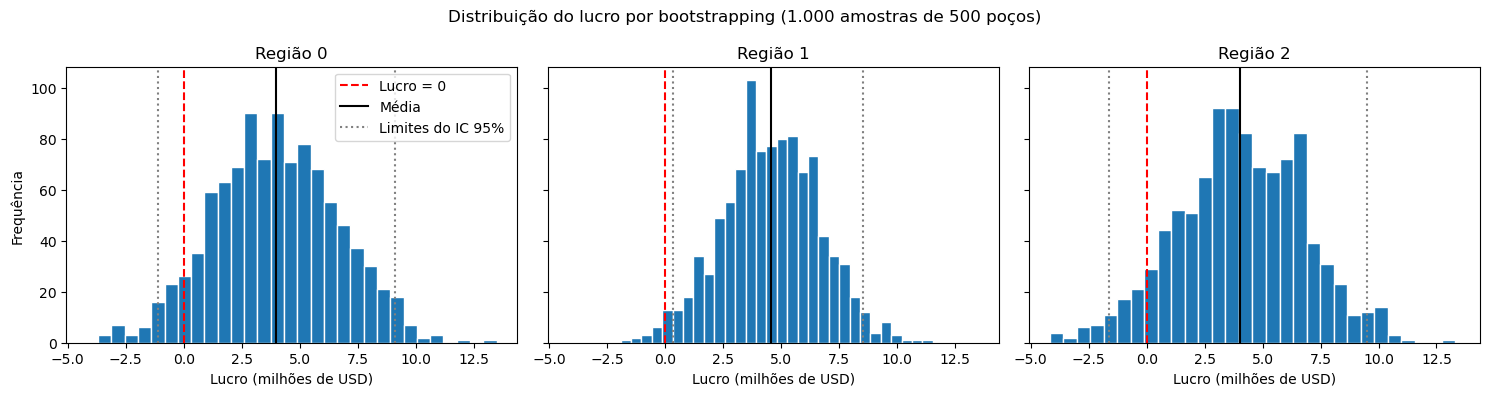

In [215]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, (region, values) in zip(axes, bootstrap_results.items()):
    lower = np.percentile(values, (1 - CONFIDENCE) / 2 * 100) / 1e6
    upper = np.percentile(values, (1 + CONFIDENCE) / 2 * 100) / 1e6

    ax.hist(values / 1e6, bins=30, edgecolor='white')
    ax.axvline(0, color='red', linestyle='--', label='Lucro = 0')
    ax.axvline(values.mean() / 1e6, color='black', label='Média')
    ax.axvline(lower, color='gray', linestyle=':', label='Limites do IC 95%')
    ax.axvline(upper, color='gray', linestyle=':')
    ax.set_title(region)
    ax.set_xlabel('Lucro (milhões de USD)')
axes[0].set_ylabel('Frequência')
axes[0].legend()
fig.suptitle(f'Distribuição do lucro por bootstrapping ({N_BOOTSTRAP:,} amostras de {N_EXPLORE} poços)'.replace(',', '.'))
plt.tight_layout()
plt.show()

### 5.4 Escolha da região pelas regras de negócio

In [216]:
eligible = final_table_raw[final_table_raw['Risco de prejuízo (%)'] < LOSS_RISK_LIMIT]

if eligible.empty:
    print(f'Nenhuma região atende ao critério de risco < {LOSS_RISK_LIMIT}%.')
else:
    best_region = eligible['Lucro médio (milhões de USD)'].idxmax()
    print(f'Região recomendada: {best_region}')
    display(eligible.loc[[best_region]].round(2))

Região recomendada: Região 1


,Lucro médio (milhões de USD),IC 95% inferior (milhões de USD),IC 95% superior (milhões de USD),Risco de prejuízo (%),"Risco < 2,5%?"
Região 1,4.56,0.34,8.52,1.5,True


### 5.5 Conclusão da seleção por bootstrapping
Com 1.000 amostras de 500 poços e seleção dos 200 melhores pelas predições, os lucros médios foram de US$ 3,96 milhões (Região 0), US$ 4,56 milhões (Região 1) e US$ 4,04 milhões (Região 2). O risco de prejuízo foi de 6,9%, 1,5% e 7,6%, respectivamente. Apenas a Região 1 atende ao critério de risco inferior a 2,5%, e ela também apresenta o maior lucro médio. O intervalo de confiança de 95% da Região 1 vai de US$ 0,34 a US$ 8,52 milhões, ou seja, é inteiramente positivo. Nas Regiões 0 e 2, os intervalos (de -US$ 1,11 a US$ 9,10 milhões e de -US$ 1,63 a US$ 9,50 milhões) incluem cenários de prejuízo, e por isso elas foram descartadas.

Essa diferença de risco é coerente com a precisão dos modelos. Na Região 1, o REQM de 0,89 mil barris permite que a seleção dos 200 melhores poços de cada amostra realmente recaia sobre os poços mais ricos. Nas Regiões 0 e 2, o REQM de cerca de 38 a 40 mil barris faz com que parte dos poços escolhidos tenha, na realidade, volume menor que o previsto, o que torna o lucro muito variável entre as amostras.

**Recomendação:** a Região 1 é a indicada para o desenvolvimento de novos poços, por ser a única que respeita o limite de risco e por ter o maior lucro médio entre as elegíveis.

**Comparação com a etapa 4.3:** a escolha não coincide com a anterior. Na etapa 4.3, a Região 0 tinha o maior lucro potencial (US$ 33,2 milhões), mas aquele cálculo selecionava os 200 melhores entre cerca de 25.000 poços e não considerava a incerteza. O bootstrapping simula a exploração de apenas 500 pontos e incorpora o risco, o que muda a decisão.

**Ressalva:** a margem de lucro é pequena nas três regiões frente ao investimento de US$ 100 milhões. Um lucro médio de cerca de US$ 4 milhões corresponde a um volume real médio de aproximadamente 116 mil barris por poço, pouco acima do ponto de equilíbrio (111,1). Além disso, as diferenças entre os lucros médios são pequenas (3,96 a 4,56), então o que decide a escolha é principalmente o critério de risco.



## Conclusão geral
Neste projeto, foram treinados modelos de regressão linear para prever o volume de reservas em três regiões. O modelo da Região 1 foi muito preciso (REQM de 0,89 mil barris), enquanto os das Regiões 0 e 2 tiveram erro elevado (cerca de 41% do volume médio). Como o volume médio das regiões (92,5, 68,8 e 95,0 mil barris) fica abaixo do ponto de equilíbrio de 111,1 mil barris por poço, o lucro depende de selecionar os melhores poços usando o modelo. Na seleção dos 200 melhores entre todos os poços de validação, a Região 0 apresentou o maior lucro potencial. Porém, ao avaliar o risco por bootstrapping, apenas a Região 1 ficou abaixo do limite de 2,5% de probabilidade de prejuízo (1,5%), com lucro médio de US$ 4,56 milhões. Recomenda-se, portanto, a Região 1, ressaltando que o lucro esperado é modesto em relação ao investimento e que os resultados dependem de os dados sintéticos refletirem a realidade.